# Metric Stat Analysis – PPP Radar Evaluation

Loads pre-exported HDF5 evaluation files (`rank00.h5` – `rank03.h5`) produced by
the metric evaluation pipeline and provides first-look visualisation of
`img`, `pred_lambda`, and `gt_support` per sample.

Each h5 file organises samples as:
```
sample_XXXXXX/
    img          (H, W, 3)  uint8
    pred_lambda  (H, W)     float32
    gt_support   (H, W)     float32
```

## 1 · Import Required Libraries

In [1]:
import os
import glob
import h5py
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import binary_dilation

plt.rcParams["figure.figsize"] = (18, 5)
plt.rcParams["image.cmap"] = "hot"

## 2 · Configuration & Path Setup

In [2]:

# ---------------------------------------------------------------------------
# Paths – one entry per model run
# ---------------------------------------------------------------------------

H5_DIRS = {
    "test_gen_data_meric_13600264": (
        "/mnt/c/Users/uik04723/Repositories/gen_data_metric"
        "/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test"
    ),
    # "my_next_model": "/mnt/c/Users/uik04723/Repositories/gen_data_metric/...",
}

# Select which model to analyse
ACTIVE_MODEL = "test_gen_data_meric_13600264"

H5_DIR = H5_DIRS[ACTIVE_MODEL]
assert os.path.isdir(H5_DIR), f"H5 directory not found: {H5_DIR}"

# ---------------------------------------------------------------------------
# Display parameters
# ---------------------------------------------------------------------------

# Radius (pixels) used to dilate each GT point for visibility.
# Increase to make GT dots larger in the output image.
GT_DILATION_RADIUS = 1

# ---------------------------------------------------------------------------
# Collect h5 files
# ---------------------------------------------------------------------------

h5_files = sorted(glob.glob(os.path.join(H5_DIR, "rank*.h5")))

print(f"Active model : {ACTIVE_MODEL}")
print(f"H5_DIR       : {H5_DIR}")
print(f"\nFound {len(h5_files)} h5 file(s):")
for p in h5_files:
    print(" ", p)

print(f"\nGT_DILATION_RADIUS = {GT_DILATION_RADIUS}  (display only)")


Active model : test_gen_data_meric_13600264
H5_DIR       : /mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test

Found 4 h5 file(s):
  /mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test/rank00.h5
  /mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test/rank01.h5
  /mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test/rank02.h5
  /mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test/rank03.h5

GT_DILATION_RADIUS = 1  (display only)


## 3 · H5 Helper – List & Load Samples

In [3]:
def list_h5_samples(h5_paths):
    """
    Return a list of (h5_path, sample_key) tuples across all rank files,
    sorted globally by sample key.
    """
    entries = []
    for path in h5_paths:
        with h5py.File(path, "r") as f:
            for key in sorted(f.keys()):
                entries.append((path, key))
    return entries


def load_h5_sample(h5_path, sample_key):
    """
    Load one sample from an h5 file.

    Returns a dict with:
      img          – (H, W, 3) uint8
      pred_lambda  – (H, W) float32   [lambda(x), i.e. predicted intensity]
      gt_support   – (H, W) float32   [binary point support {0,1}]
      ppp          – derived diagnostics dict
    """
    with h5py.File(h5_path, "r") as f:
        grp = f[sample_key]
        img         = grp["img"][:]           # (H, W, 3) uint8
        pred_lambda = grp["pred_lambda"][:]   # (H, W)    float32
        gt_support  = grp["gt_support"][:]    # (H, W)    float32

    H, W = pred_lambda.shape
    expected_count = float(pred_lambda.sum())
    gt_count       = int(gt_support.sum())

    return {
        "img":         img,
        "pred_lambda": pred_lambda,
        "gt_support":  gt_support,
        "ppp": {
            "H":              H,
            "W":              W,
            "img_area":       H * W,
            "expected_count": expected_count,
            "gt_count":       gt_count,
            "count_error":    expected_count - gt_count,
        },
        "meta": {
            "h5_file":    os.path.basename(h5_path),
            "sample_key": sample_key,
        },
    }


# Build global sample index
all_samples = list_h5_samples(h5_files)
print(f"Total samples across all rank files: {len(all_samples)}")
print("First 5 entries:")
for entry in all_samples[:5]:
    print(f"  {os.path.basename(entry[0])} / {entry[1]}")

Total samples across all rank files: 500
First 5 entries:
  rank00.h5 / sample_000000
  rank00.h5 / sample_000001
  rank00.h5 / sample_000002
  rank00.h5 / sample_000003
  rank00.h5 / sample_000004


## 4 · PPP Sampling Methods

In [4]:
def sample_ppp_by_thinning(
    lambda_grid: np.ndarray,
    *,
    pixel_area: float | None = None,
    rng: np.random.Generator | None = None,
):
    """
    Sample an inhomogeneous PPP using thinning from a homogeneous PPP.

    Parameters
    ----------
    lambda_grid : (H, W) array
        Intensity lambda(x) per pixel (mass per pixel, non-negative).
    pixel_area : float
        Kept for API compatibility, not used.
    rng : np.random.Generator

    Returns
    -------
    points_xy  : (N, 2) array  – accepted points in image coords (x, y)
    N          : int
    lambda_max : float
    N_prop     : int           – number of proposals before thinning
    """
    if rng is None:
        rng = np.random.default_rng()

    lam = np.asarray(lambda_grid, dtype=np.float64)
    assert np.all(lam >= 0)
    H, W = lam.shape

    lambda_max = lam.max()
    if lambda_max == 0:
        return np.zeros((0, 2)), 0, 0.0, 0

    area_total = H * W
    Lambda_hom = lambda_max * area_total
    N_prop = rng.poisson(Lambda_hom)

    if N_prop == 0:
        return np.zeros((0, 2)), 0, lambda_max, 0

    xs = rng.random(N_prop) * W
    ys = rng.random(N_prop) * H
    xi = np.clip(xs.astype(int), 0, W - 1)
    yi = np.clip(ys.astype(int), 0, H - 1)

    lam_x = lam[yi, xi]
    accept_prob = lam_x / lambda_max
    keep = rng.random(N_prop) < accept_prob

    points_xy = np.stack([xs[keep], ys[keep]], axis=1)
    return points_xy, points_xy.shape[0], float(lambda_max), N_prop


def sample_points_block_bernoulli(
    lambda_grid: np.ndarray,
    *,
    block_size: int = 8,
    pixel_area: float = 1.0,
    placement: str = "weighted",
    rng: np.random.Generator | None = None,
):
    """
    Block/Bernoulli approximation of a PPP.

    For each block A:
        Λ_A = sum_A λ * pixel_area
        Activate with p_A = 1 - exp(-Λ_A)
    If active, place exactly one point in A.

    Parameters
    ----------
    lambda_grid : (H, W) array  – intensity mass per pixel
    block_size  : int           – side length of each block in pixels
    pixel_area  : float         – set to 1.0 when lambda_grid is already mass per pixel
    placement   : "weighted" | "uniform"

    Returns
    -------
    points_xy : (N, 2) array
    stats     : dict
    """
    if rng is None:
        rng = np.random.default_rng()

    lam = np.asarray(lambda_grid, dtype=np.float64)
    if lam.ndim != 2:
        raise ValueError("lambda_grid must be 2D.")
    if not np.all(np.isfinite(lam)):
        raise ValueError("lambda_grid contains NaN/Inf.")
    if np.any(lam < 0):
        raise ValueError("lambda_grid contains negative values.")
    if placement not in {"weighted", "uniform"}:
        raise ValueError("placement must be 'weighted' or 'uniform'")

    bs = int(block_size)
    H, W = lam.shape
    nby = (H + bs - 1) // bs
    nbx = (W + bs - 1) // bs
    num_blocks = nby * nbx

    Hp, Wp = nby * bs, nbx * bs
    if Hp != H or Wp != W:
        lam_pad = np.zeros((Hp, Wp), dtype=np.float64)
        lam_pad[:H, :W] = lam
    else:
        lam_pad = lam

    lam_blocks = lam_pad.reshape(nby, bs, nbx, bs).transpose(0, 2, 1, 3)
    block_sums = lam_blocks.sum(axis=(2, 3)) * pixel_area  # (nby, nbx)

    p_active = 1.0 - np.exp(-block_sums)
    expected_blocks_active = float(p_active.sum())

    active_mask = rng.random(size=(nby, nbx)) < p_active
    active_by, active_bx = np.nonzero(active_mask)
    num_active = active_by.size

    if num_active == 0:
        return np.zeros((0, 2), dtype=np.float64), dict(
            block_size=bs, placement=placement,
            num_blocks=num_blocks, num_active_blocks=0,
            expected_active_blocks=expected_blocks_active, num_points=0,
        )

    points_xy = np.empty((num_active, 2), dtype=np.float64)
    x0s = active_bx * bs
    y0s = active_by * bs
    wBs = np.minimum(bs, W - x0s)
    hBs = np.minimum(bs, H - y0s)

    if placement == "uniform":
        points_xy[:, 0] = x0s + rng.random(num_active) * wBs
        points_xy[:, 1] = y0s + rng.random(num_active) * hBs
    else:
        for i, (by, bx, x0, y0, wB, hB) in enumerate(
            zip(active_by, active_bx, x0s, y0s, wBs, hBs)
        ):
            block = lam[y0:y0 + hB, x0:x0 + wB]
            s = block.sum()
            if s <= 0:
                points_xy[i, 0] = x0 + rng.random() * wB
                points_xy[i, 1] = y0 + rng.random() * hB
                continue
            probs = block.ravel() / s
            idx = rng.choice(probs.size, p=probs)
            py, px = divmod(idx, wB)
            points_xy[i, 0] = x0 + px + rng.random()
            points_xy[i, 1] = y0 + py + rng.random()

    return points_xy, dict(
        block_size=bs, placement=placement,
        num_blocks=num_blocks, num_active_blocks=int(num_active),
        expected_active_blocks=expected_blocks_active, num_points=int(num_active),
    )

print("Sampling functions loaded: sample_ppp_by_thinning, sample_points_block_bernoulli")


Sampling functions loaded: sample_ppp_by_thinning, sample_points_block_bernoulli


## 4 · Load & Display First Sample: Image, Lambda, GT

Sample : rank00.h5  /  sample_000000
Shape  : img=(544, 1792, 3)  pred_lambda=(544, 1792)  gt_support=(544, 1792)
PPP    : E[N]=106.85  GT=67  err=+39.85


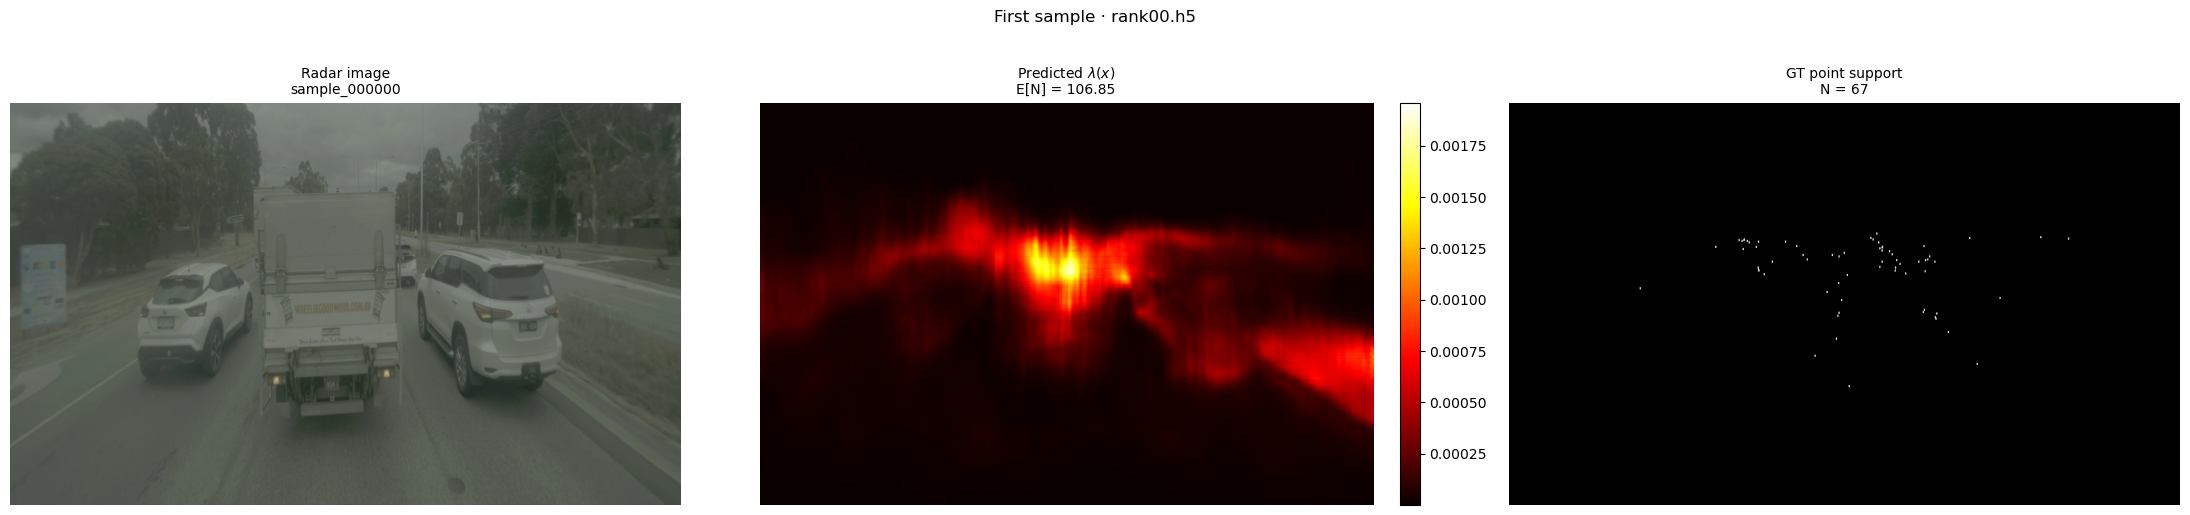

In [5]:
# Load first sample
h5_path_0, key_0 = all_samples[0]
sample = load_h5_sample(h5_path_0, key_0)

img         = sample["img"]
pred_lambda = sample["pred_lambda"]
gt_support  = sample["gt_support"]   # original – untouched
ppp         = sample["ppp"]
meta        = sample["meta"]

print(f"Sample : {meta['h5_file']}  /  {meta['sample_key']}")
print(f"Shape  : img={img.shape}  pred_lambda={pred_lambda.shape}  gt_support={gt_support.shape}")
print(f"PPP    : E[N]={ppp['expected_count']:.2f}  GT={ppp['gt_count']}  err={ppp['count_error']:+.2f}")

# GT point coordinates (row=y, col=x)
gt_ys, gt_xs = np.where(gt_support > 0)

# --- Side-by-side plot ---
fig, axes = plt.subplots(1, 3, figsize=(22, 5))

ax = axes[0]
ax.imshow(img, aspect="auto")
ax.set_title(f"Radar image\n{meta['sample_key']}", fontsize=10)
ax.axis("off")

ax = axes[1]
im = ax.imshow(pred_lambda, cmap="hot", aspect="auto")
ax.set_title(
    r"Predicted $\lambda(x)$"
    f"\nE[N] = {ppp['expected_count']:.2f}",
    fontsize=10,
)
ax.axis("off")
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

ax = axes[2]
_struct = np.ones((2 * GT_DILATION_RADIUS + 1, 2 * GT_DILATION_RADIUS + 1), dtype=bool)
_gt_vis = binary_dilation(gt_support > 0, structure=_struct)
gt_rgb = np.zeros((*gt_support.shape, 3), dtype=np.uint8)
gt_rgb[_gt_vis] = 255
ax.imshow(gt_rgb, aspect="auto")
ax.set_title(
    f"GT point support\nN = {ppp['gt_count']}",
    fontsize=10,
)
ax.axis("off")

plt.suptitle(f"First sample · {meta['h5_file']}", fontsize=12, y=1.02)


plt.tight_layout()
plt.show()

## 5 · Interactive Sample Browser

Use the slider to step through samples. Click **"Add to selection"** to mark the current sample. The selected keys are collected in `selected_samples` (printed in the cell below).

In [6]:
import ipywidgets as widgets
from IPython.display import display, clear_output

# ── persistent selection list ────────────────────────────────────────────────
selected_samples = []   # list of (h5_file, sample_key)

# ── widgets ──────────────────────────────────────────────────────────────────
n = len(all_samples)

slider = widgets.IntSlider(
    value=0, min=0, max=n - 1, step=1,
    description="Sample:",
    continuous_update=False,
    layout=widgets.Layout(width="600px"),
)

btn_add = widgets.ToggleButton(
    value=False,
    description="☆  Add to selection",
    button_style="",
    layout=widgets.Layout(width="180px"),
)

lbl_status = widgets.Label(value=f"0 / {n} selected")

plot_out   = widgets.Output()
select_out = widgets.Output()


def _update_btn_label(idx):
    """Reflect whether the current sample is already in the selection."""
    h5_path, key = all_samples[idx]
    entry = (os.path.basename(h5_path), key)
    btn_add.value       = entry in selected_samples
    btn_add.description = "★  In selection" if btn_add.value else "☆  Add to selection"
    btn_add.button_style = "success" if btn_add.value else ""


def _render(idx):
    h5_path, key = all_samples[idx]
    sample = load_h5_sample(h5_path, key)

    img         = sample["img"]
    pred_lambda = sample["pred_lambda"]
    gt_support  = sample["gt_support"]
    ppp         = sample["ppp"]
    meta        = sample["meta"]

    gt_ys, gt_xs = np.where(gt_support > 0)

    with plot_out:
        clear_output(wait=True)
        fig, axes = plt.subplots(1, 3, figsize=(22, 5))

        axes[0].imshow(img, aspect="auto")
        axes[0].set_title(f"Radar image\n{meta['sample_key']}", fontsize=10)
        axes[0].axis("off")

        im = axes[1].imshow(pred_lambda, cmap="hot", aspect="auto")
        axes[1].set_title(
            r"Predicted $\lambda(x)$" + f"\nE[N] = {ppp['expected_count']:.2f}",
            fontsize=10,
        )
        axes[1].axis("off")
        plt.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)

        _struct = np.ones((2 * GT_DILATION_RADIUS + 1, 2 * GT_DILATION_RADIUS + 1), dtype=bool)
        _gt_vis = binary_dilation(gt_support > 0, structure=_struct)
        _gt_rgb = np.zeros((*gt_support.shape, 3), dtype=np.uint8)
        _gt_rgb[_gt_vis] = 255
        axes[2].imshow(_gt_rgb, aspect="auto")
        axes[2].set_title(
            f"GT support\nN = {ppp['gt_count']}",
            fontsize=10,
        )
        axes[2].axis("off")

        plt.suptitle(
            f"[{idx + 1}/{n}]  {meta['h5_file']}  ·  {meta['sample_key']}"
            f"   |   E[N]={ppp['expected_count']:.2f}  GT={ppp['gt_count']}"
            f"  err={ppp['count_error']:+.2f}",
            fontsize=11, y=1.02,
        )
        plt.tight_layout()
        plt.show()


def _refresh_selection_output():
    with select_out:
        clear_output(wait=True)
        if selected_samples:
            print(f"Selected ({len(selected_samples)}):")
            for h5f, k in selected_samples:
                print(f"  {h5f}  /  {k}")
        else:
            print("No samples selected yet.")


def on_slider_change(change):
    _update_btn_label(change["new"])
    _render(change["new"])


def on_toggle_change(change):
    idx = slider.value
    h5_path, key = all_samples[idx]
    entry = (os.path.basename(h5_path), key)

    if change["new"]:                          # toggled ON → add
        if entry not in selected_samples:
            selected_samples.append(entry)
        btn_add.description  = "★  In selection"
        btn_add.button_style = "success"
    else:                                      # toggled OFF → remove
        if entry in selected_samples:
            selected_samples.remove(entry)
        btn_add.description  = "☆  Add to selection"
        btn_add.button_style = ""

    lbl_status.value = f"{len(selected_samples)} / {n} selected"
    _refresh_selection_output()


slider.observe(on_slider_change, names="value")
btn_add.observe(on_toggle_change, names="value")

# ── initial render ────────────────────────────────────────────────────────────
_update_btn_label(0)
_render(0)
_refresh_selection_output()

# ── layout ────────────────────────────────────────────────────────────────────
controls = widgets.HBox([slider, btn_add, lbl_status])

display(widgets.VBox([controls, plot_out, select_out]))
# ── layout ────────────────────────────────────────────────────────────────────controls = widgets.HBox([slider, btn_add, lbl_status])display(widgets.VBox([controls, plot_out, select_out]))


In [7]:
# ── Print final selection (run this cell after browsing) ─────────────────────
print(f"selected_samples = {selected_samples!r}")


selected_samples = [('rank00.h5', 'sample_000000')]


## Analysis: Visual Inspection Variance Sampling

Takes the **first sample** from `selected_samples` and draws **two independent point clouds**
from the predicted λ heatmap — one per sampling method — displayed side by side with the GT.

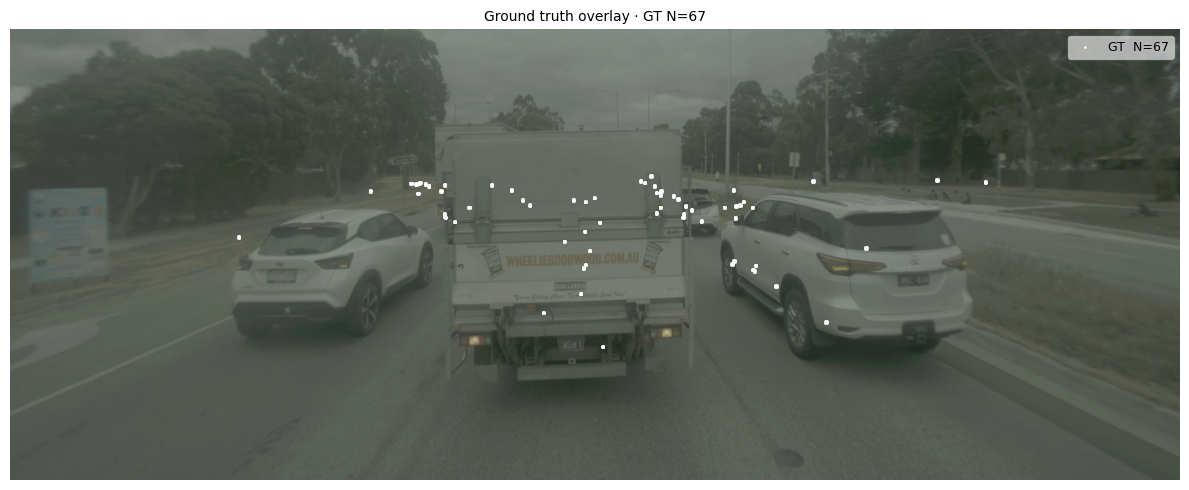

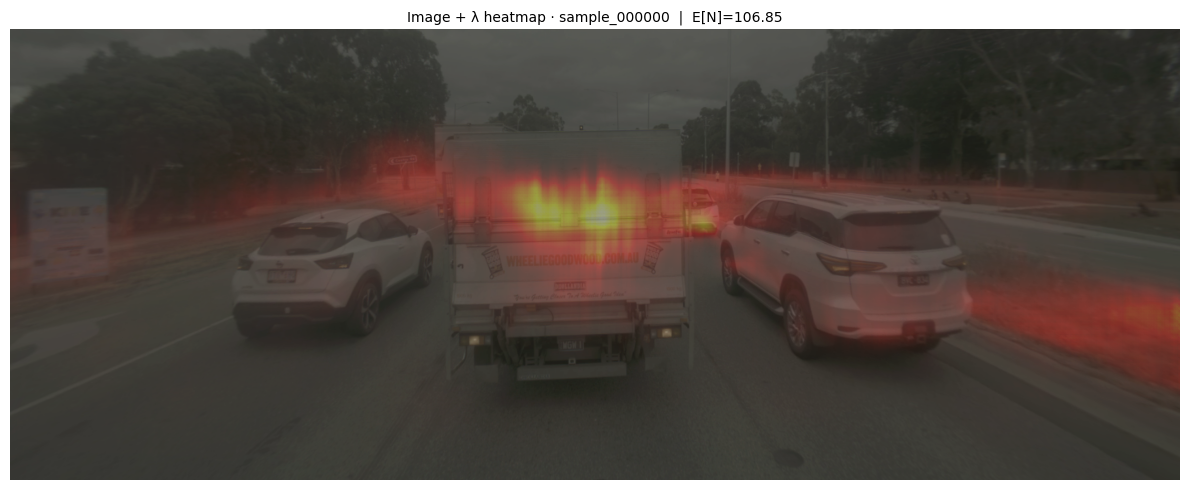

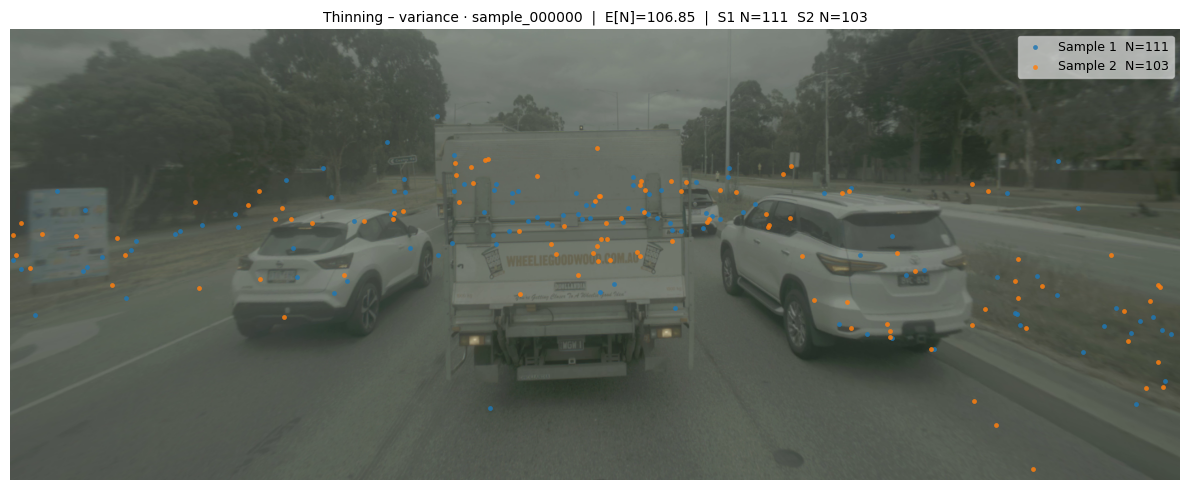

In [8]:
assert selected_samples, "No samples selected – browse and add at least one above."

# Load first selected sample
_h5_file, _key = selected_samples[0]
_h5_path = next(
    p for (p, k) in all_samples
    if os.path.basename(p) == _h5_file and k == _key
)
_sample = load_h5_sample(_h5_path, _key)

_img         = _sample["img"]
_pred_lambda = _sample["pred_lambda"]
_gt_support  = _sample["gt_support"]
_ppp         = _sample["ppp"]

H_img, W_img = _pred_lambda.shape
DOT_SIZE    = 12   # pt² for sampled points
GT_DOT_SIZE = 4    # pt² for GT points (smaller)
N_SAMPLES   = 2    # ← change this to draw more independent samples

_COLORS = plt.cm.tab10.colors  # up to 10 distinct colours

# ── N independent thinning draws ─────────────────────────────────────────────
_thin_samples = [
    sample_ppp_by_thinning(_pred_lambda, rng=np.random.default_rng(seed=i))
    for i in range(N_SAMPLES)
]

# ── shared GT coords ──────────────────────────────────────────────────────────
_struct  = np.ones((2 * GT_DILATION_RADIUS + 1, 2 * GT_DILATION_RADIUS + 1), bool)
_gt_ys, _gt_xs = np.where(binary_dilation(_gt_support > 0, structure=_struct))

# ── Plot 1: image with GT overlaid ────────────────────────────────────────────
fig_gt, ax_gt = plt.subplots(1, 1, figsize=(12, 5))
ax_gt.imshow(_img, aspect="auto", extent=[0, W_img, H_img, 0])
if _gt_ys.size > 0:
    ax_gt.scatter(_gt_xs, _gt_ys,
                  s=GT_DOT_SIZE, c="white", linewidths=0, alpha=0.9,
                  label=f"GT  N={_ppp['gt_count']}")
ax_gt.legend(loc="upper right", fontsize=9, framealpha=0.6)
ax_gt.axis("off")
ax_gt.set_title(f"Ground truth overlay · GT N={_ppp['gt_count']}", fontsize=10)
plt.tight_layout()
plt.show()

# ── Plot 2: image + faint lambda overlay ──────────────────────────────────────
fig_lam, ax_lam = plt.subplots(1, 1, figsize=(12, 5))
ax_lam.imshow(_img, aspect="auto", extent=[0, W_img, H_img, 0])
ax_lam.imshow(_pred_lambda, cmap="hot", aspect="auto",
              extent=[0, W_img, H_img, 0], alpha=0.35)
ax_lam.axis("off")
ax_lam.set_title(
    f"Image + λ heatmap · {_key}  |  E[N]={_ppp['expected_count']:.2f}",
    fontsize=10,
)
plt.tight_layout()
plt.show()

# ── Plot 3: N thinning samples overlaid on image ──────────────────────────────
fig_thin, ax_thin = plt.subplots(1, 1, figsize=(12, 5))
ax_thin.imshow(_img, aspect="auto", extent=[0, W_img, H_img, 0])
counts_str = []
for i, (pts, n, _, _) in enumerate(_thin_samples):
    if n > 0:
        ax_thin.scatter(pts[:, 0], pts[:, 1],
                        s=DOT_SIZE, c=[_COLORS[i % len(_COLORS)]],
                        linewidths=0, alpha=0.85,
                        label=f"Sample {i+1}  N={n}")
    counts_str.append(f"S{i+1} N={n}")
ax_thin.legend(loc="upper right", fontsize=9, framealpha=0.6)
ax_thin.axis("off")
ax_thin.set_title(
    f"Thinning – variance · {_key}  |  E[N]={_ppp['expected_count']:.2f}  |  "
    + "  ".join(counts_str),
    fontsize=10,
)
plt.tight_layout()
plt.show()


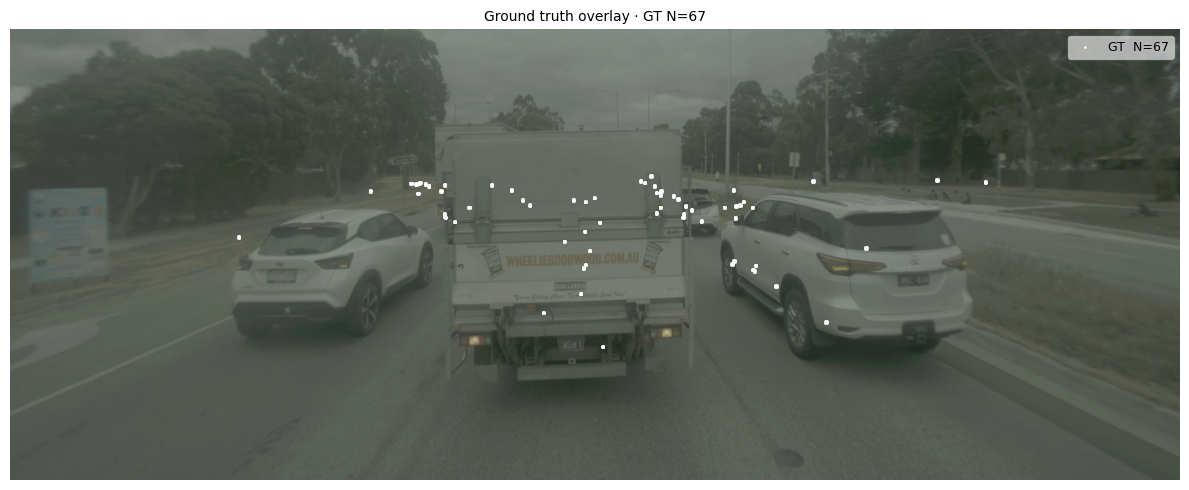

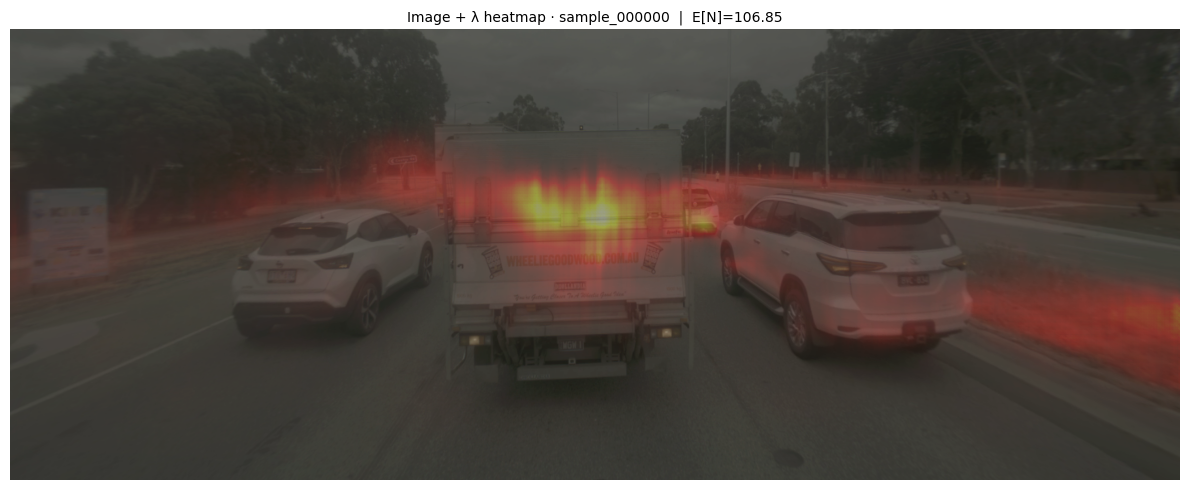

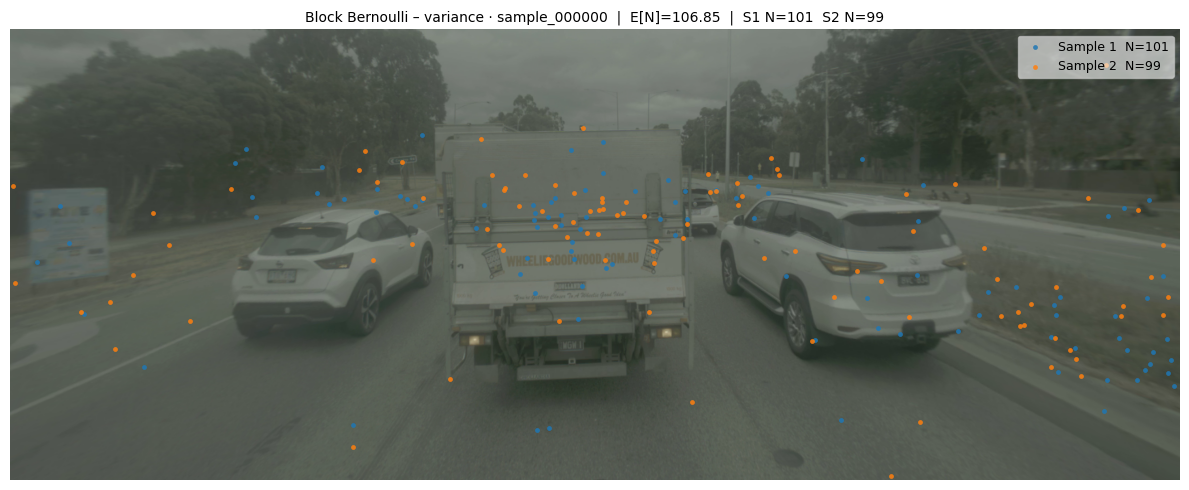

In [9]:
# ── N independent Block Bernoulli draws ──────────────────────────────────────
_bb_samples = [
    sample_points_block_bernoulli(
        _pred_lambda, block_size=8, placement="weighted",
        rng=np.random.default_rng(seed=i)
    )
    for i in range(N_SAMPLES)
]

# ── Plot 1: image with GT overlaid ────────────────────────────────────────────
fig_gt2, ax_gt2 = plt.subplots(1, 1, figsize=(12, 5))
ax_gt2.imshow(_img, aspect="auto", extent=[0, W_img, H_img, 0])
if _gt_ys.size > 0:
    ax_gt2.scatter(_gt_xs, _gt_ys,
                   s=GT_DOT_SIZE, c="white", linewidths=0, alpha=0.9,
                   label=f"GT  N={_ppp['gt_count']}")
ax_gt2.legend(loc="upper right", fontsize=9, framealpha=0.6)
ax_gt2.axis("off")
ax_gt2.set_title(f"Ground truth overlay · GT N={_ppp['gt_count']}", fontsize=10)
plt.tight_layout()
plt.show()

# ── Plot 2: image + faint lambda overlay ──────────────────────────────────────
fig_lam2, ax_lam2 = plt.subplots(1, 1, figsize=(12, 5))
ax_lam2.imshow(_img, aspect="auto", extent=[0, W_img, H_img, 0])
ax_lam2.imshow(_pred_lambda, cmap="hot", aspect="auto",
               extent=[0, W_img, H_img, 0], alpha=0.35)
ax_lam2.axis("off")
ax_lam2.set_title(
    f"Image + λ heatmap · {_key}  |  E[N]={_ppp['expected_count']:.2f}",
    fontsize=10,
)
plt.tight_layout()
plt.show()

# ── Plot 3: N block Bernoulli samples overlaid on image ───────────────────────
fig_bb, ax_bb = plt.subplots(1, 1, figsize=(12, 5))
ax_bb.imshow(_img, aspect="auto", extent=[0, W_img, H_img, 0])
counts_str = []
for i, (pts, stats) in enumerate(_bb_samples):
    n = stats["num_points"]
    if n > 0:
        ax_bb.scatter(pts[:, 0], pts[:, 1],
                      s=DOT_SIZE, c=[_COLORS[i % len(_COLORS)]],
                      linewidths=0, alpha=0.85,
                      label=f"Sample {i+1}  N={n}")
    counts_str.append(f"S{i+1} N={n}")
ax_bb.legend(loc="upper right", fontsize=9, framealpha=0.6)
ax_bb.axis("off")
ax_bb.set_title(
    f"Block Bernoulli – variance · {_key}  |  E[N]={_ppp['expected_count']:.2f}  |  "
    + "  ".join(counts_str),
    fontsize=10,
)
plt.tight_layout()
plt.show()


In [11]:
print(f"dtype      : {gt_support.dtype}")
print(f"shape      : {gt_support.shape}")
print(f"unique vals: {np.unique(gt_support)}")
print(f"min/max    : {gt_support.min():.4f} / {gt_support.max():.4f}")
print(f"nonzero px : {(gt_support > 0).sum()}")


dtype      : float32
shape      : (544, 1792)
unique vals: [0. 1.]
min/max    : 0.0000 / 1.0000
nonzero px : 67


In [27]:
# ── 5.1  Low-level helpers ───────────────────────────────────────────────────

def points_to_binary_grid(points_xy: np.ndarray, H: int, W: int) -> np.ndarray:
    """
    Convert a point cloud to a binary occupancy grid.

    Parameters
    ----------
    points_xy : (N, 2) float array
        Point coordinates in image space (x = column, y = row).
        May be empty (shape (0, 2)).
    H, W : int
        Grid dimensions.

    Returns
    -------
    grid : (H, W) float64 array with values in {0.0, 1.0}.
        Multiple points falling on the same pixel are collapsed to 1.
    """
    grid = np.zeros((H, W), dtype=np.float64)
    if points_xy.shape[0] > 0:
        xi = np.clip(points_xy[:, 0].astype(int), 0, W - 1)
        yi = np.clip(points_xy[:, 1].astype(int), 0, H - 1)
        grid[yi, xi] = 1.0
    return grid


def random_unit_vectors(
    n_projections: int,
    D: int,
    rng: np.random.Generator | None = None,
) -> np.ndarray:
    """
    Sample `n_projections` random unit vectors from the uniform distribution
    on the unit sphere in R^D (i.e. normalised Gaussian draws).

    Parameters
    ----------
    n_projections : int
    D             : int – dimensionality (= H * W)
    rng           : np.random.Generator

    Returns
    -------
    vecs : (n_projections, D) float64 array, each row has L2-norm == 1.
    """
    if rng is None:
        rng = np.random.default_rng()
    vecs = rng.standard_normal((n_projections, D))          # (P, D)
    norms = np.linalg.norm(vecs, axis=1, keepdims=True)     # (P, 1)
    # guard against the astronomically unlikely all-zero draw
    norms = np.where(norms == 0.0, 1.0, norms)
    return vecs / norms                                      # (P, D)


def project_samples(
    samples_flat: np.ndarray,
    projection_vectors: np.ndarray,
) -> np.ndarray:
    """
    Project every sample onto every projection vector via dot product.

    Parameters
    ----------
    samples_flat       : (n_samples, D) float array
        Each row is a flattened binary occupancy map.
    projection_vectors : (n_projections, D) float array
        Each row is a unit vector.

    Returns
    -------
    projections : (n_samples, n_projections) float array
        projections[i, k] = <samples_flat[i], projection_vectors[k]>
    """
    return samples_flat @ projection_vectors.T              # (n, P)


def gt_quantile_per_projection(
    gt_proj: np.ndarray,
    sample_proj: np.ndarray,
) -> np.ndarray:
    """
    For each projection direction, compute the empirical quantile of the GT
    scalar projection among the scalar projections of the generated samples.

    Parameters
    ----------
    gt_proj     : (n_projections,) float array
        Scalar projection value of the single GT map.
    sample_proj : (n_samples, n_projections) float array
        Scalar projection values for each generated sample and direction.

    Returns
    -------
    quantiles : (n_projections,) float array in [0, 1]
        quantiles[k] = fraction of generated samples whose projection
        onto direction k is <= the GT projection onto direction k.
    """
    return (sample_proj <= gt_proj[np.newaxis, :]).mean(axis=0)  # (P,)


print("Helpers loaded: points_to_binary_grid, random_unit_vectors, "
      "project_samples, gt_quantile_per_projection")

Helpers loaded: points_to_binary_grid, random_unit_vectors, project_samples, gt_quantile_per_projection


In [28]:
# ── 5.2  Main evaluation function ────────────────────────────────────────────

def evaluate_projections(
    pred_lambda: np.ndarray,
    gt_support: np.ndarray,
    *,
    n_samples: int = 200,
    n_projections: int = 500,
    sampling_fn=None,
    rng: np.random.Generator | None = None,
) -> dict:
    """
    Projection-based evaluation of a predicted intensity map against a GT
    binary occupancy map.

    Parameters
    ----------
    pred_lambda   : (H, W) float array
        Predicted intensity heatmap (lambda per pixel, non-negative).
    gt_support    : (H, W) array
        Binary ground-truth occupancy map with values in {0, 1}.
    n_samples     : int
        Number of binary occupancy maps to sample from `pred_lambda`.
    n_projections : int
        Number of random projection directions in R^(H*W).
    sampling_fn   : callable(lam, rng) -> (points_xy, stats)
        Function that draws one point-cloud sample from `pred_lambda`.
        Defaults to block-Bernoulli with block_size=8, placement="weighted".
    rng           : np.random.Generator
        Master RNG; child seeds are derived from it so results are
        fully reproducible when a seeded generator is supplied.

    Returns
    -------
    result : dict with keys
        quantiles          (n_projections,)           – empirical quantile of GT
        gt_projections     (n_projections,)           – GT scalar projections
        sample_projections (n_samples, n_projections) – sample scalar projections
        projection_vectors (n_projections, D)          – unit vectors used
        n_samples, n_projections, H, W, D              int
    """
    if rng is None:
        rng = np.random.default_rng()

    H, W = pred_lambda.shape
    D = H * W

    # ── default sampler ──────────────────────────────────────────────────────
    if sampling_fn is None:
        def sampling_fn(lam, child_rng):
            pts, stats = sample_points_block_bernoulli(
                lam, block_size=8, placement="weighted", rng=child_rng
            )
            return pts, stats

    # ── Step 1: generate n_samples binary occupancy maps ─────────────────────
    child_seeds = rng.integers(0, 2**32, size=n_samples)
    sampled_flat = np.empty((n_samples, D), dtype=np.float64)
    for i, seed in enumerate(child_seeds):
        pts, _ = sampling_fn(pred_lambda, np.random.default_rng(int(seed)))
        sampled_flat[i] = points_to_binary_grid(pts, H, W).ravel()

    # ── Step 2: generate n_projections random unit vectors in R^D ────────────
    proj_vecs = random_unit_vectors(n_projections, D, rng=rng)     # (P, D)

    # ── Step 3: flatten GT ────────────────────────────────────────────────────
    gt_flat = gt_support.astype(np.float64).ravel()[np.newaxis, :] # (1, D)

    # ── Step 4: project GT and generated samples ──────────────────────────────
    gt_proj   = project_samples(gt_flat, proj_vecs)[0]             # (P,)
    samp_proj = project_samples(sampled_flat, proj_vecs)           # (n, P)

    # ── Step 5: empirical quantile of GT per projection ───────────────────────
    quantiles = gt_quantile_per_projection(gt_proj, samp_proj)     # (P,)

    return dict(
        quantiles          = quantiles,
        gt_projections     = gt_proj,
        sample_projections = samp_proj,
        projection_vectors = proj_vecs,
        n_samples          = n_samples,
        n_projections      = n_projections,
        H=H, W=W, D=D,
    )

print("evaluate_projections loaded.")

evaluate_projections loaded.


### 5.3 · Single-projection CDF demo

Draw one random projection direction, project all generated samples onto it to form an empirical CDF, then mark where the GT lands on that CDF.

GT projection value : 0.0017
GT quantile         : 0.590  (GT is above 59.0% of samples along this direction)


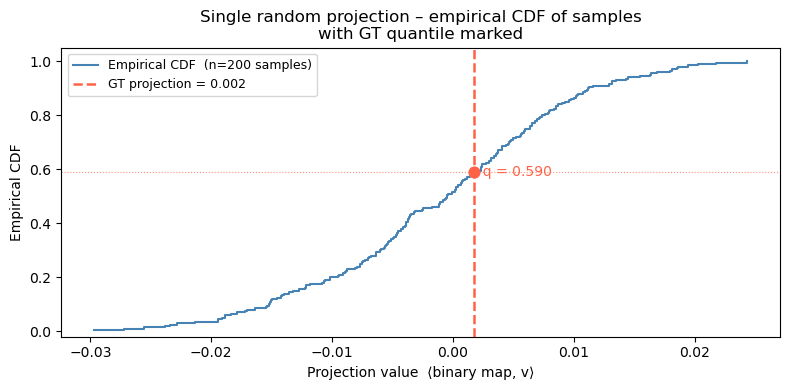

In [29]:
# ── Parameters ───────────────────────────────────────────────────────────────
N_SAMP_EVAL   = 200   # number of binary samples drawn from pred_lambda
PROJ_RNG_SEED = 0     # set to None for a different draw each run

rng = np.random.default_rng(PROJ_RNG_SEED)

H, W = pred_lambda.shape
D    = H * W

# ── Step 1: one random unit projection vector ─────────────────────────────────
v = random_unit_vectors(1, D, rng=rng)[0]          # (D,)

# ── Step 2: generate N binary samples and project them ───────────────────────
child_seeds  = rng.integers(0, 2**32, size=N_SAMP_EVAL)
sample_projs = np.empty(N_SAMP_EVAL, dtype=np.float64)

for i, seed in enumerate(child_seeds):
    pts, _ = sample_points_block_bernoulli(
        pred_lambda, block_size=8, placement="weighted",
        rng=np.random.default_rng(int(seed)),
    )
    sample_projs[i] = points_to_binary_grid(pts, H, W).ravel() @ v

# ── Step 3: project the GT ────────────────────────────────────────────────────
gt_proj = gt_support.astype(np.float64).ravel() @ v  # scalar

# ── Step 4: quantile of GT among samples ─────────────────────────────────────
gt_quantile = (sample_projs <= gt_proj).mean()
print(f"GT projection value : {gt_proj:.4f}")
print(f"GT quantile         : {gt_quantile:.3f}  "
      f"(GT is above {gt_quantile*100:.1f}% of samples along this direction)")

# ── Plot: empirical CDF of sample projections + GT marker ────────────────────
sorted_s = np.sort(sample_projs)
cdf_y    = np.arange(1, N_SAMP_EVAL + 1) / N_SAMP_EVAL   # (0, 1]

fig_cdf, ax_cdf = plt.subplots(figsize=(8, 4))

ax_cdf.step(sorted_s, cdf_y, where="post", color="steelblue", linewidth=1.5,
            label=f"Empirical CDF  (n={N_SAMP_EVAL} samples)")

# vertical line at GT projection value
ax_cdf.axvline(gt_proj, color="tomato", linewidth=1.8, linestyle="--",
               label=f"GT projection = {gt_proj:.3f}")

# horizontal line at the GT quantile
ax_cdf.axhline(gt_quantile, color="tomato", linewidth=0.8, linestyle=":",
               alpha=0.7)

# annotation dot at the intersection
ax_cdf.scatter([gt_proj], [gt_quantile], color="tomato", zorder=5, s=60)
ax_cdf.annotate(
    f"  q = {gt_quantile:.3f}",
    xy=(gt_proj, gt_quantile),
    fontsize=10, color="tomato", va="center",
)

ax_cdf.set_xlabel("Projection value  ⟨binary map, v⟩")
ax_cdf.set_ylabel("Empirical CDF")
ax_cdf.set_title("Single random projection – empirical CDF of samples\nwith GT quantile marked")
ax_cdf.legend(fontsize=9)
ax_cdf.set_ylim(-0.02, 1.05)

plt.tight_layout()
plt.show()

n_projections : 200
n_samples     : 200
mean quantile : 0.4819  (ideal ≈ 0.50)
std           : 0.2737  (ideal ≈ 0.289)
frac [.05,.95]: 0.945  (ideal ≈ 0.90)


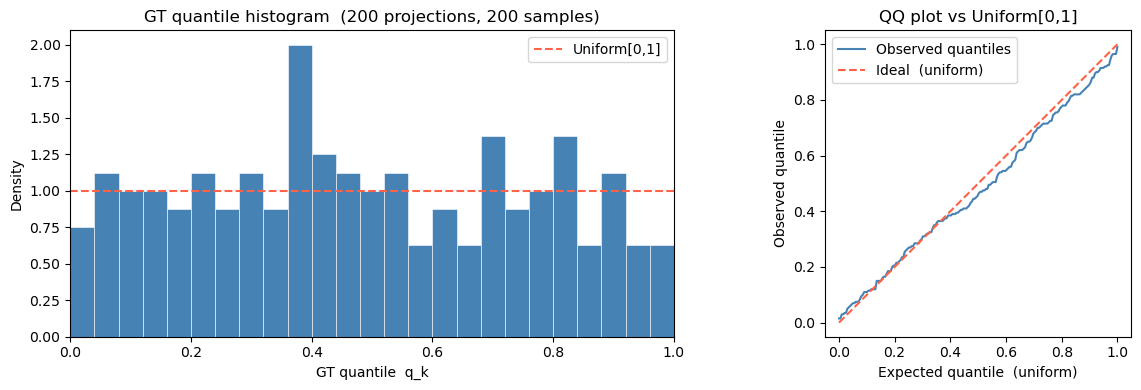

In [33]:
# ── Parameters ───────────────────────────────────────────────────────────────
N_PROJ_EVAL   = 200   # number of random projection directions
N_SAMP_EVAL   = 200   # number of binary samples per projection
PROJ_RNG_SEED = 0

# ── Run evaluate_projections ──────────────────────────────────────────────────
proj_result = evaluate_projections(
    pred_lambda,
    gt_support,
    n_samples     = N_SAMP_EVAL,
    n_projections = N_PROJ_EVAL,
    rng           = np.random.default_rng(PROJ_RNG_SEED),
)
q = proj_result["quantiles"]   # (P,) – one quantile per projection

# ── Summary stats ─────────────────────────────────────────────────────────────
print(f"n_projections : {N_PROJ_EVAL}")
print(f"n_samples     : {N_SAMP_EVAL}")
print(f"mean quantile : {q.mean():.4f}  (ideal ≈ 0.50)")
print(f"std           : {q.std():.4f}  (ideal ≈ 0.289)")
print(f"frac [.05,.95]: {((q >= 0.05) & (q <= 0.95)).mean():.3f}  (ideal ≈ 0.90)")

# ── Plot ──────────────────────────────────────────────────────────────────────
fig_mq, axes_mq = plt.subplots(1, 2, figsize=(13, 4))

# Left – histogram of quantiles vs Uniform[0,1]
axes_mq[0].hist(q, bins=25, range=(0, 1), color="steelblue", edgecolor="white",
                linewidth=0.4, density=True)
axes_mq[0].axhline(1.0, color="tomato", linewidth=1.5, linestyle="--",
                   label="Uniform[0,1]")
axes_mq[0].set_xlabel("GT quantile  q_k")
axes_mq[0].set_ylabel("Density")
axes_mq[0].set_title(f"GT quantile histogram  ({N_PROJ_EVAL} projections, {N_SAMP_EVAL} samples)")
axes_mq[0].set_xlim(0, 1)
axes_mq[0].legend()

# Right – sorted quantile plot (QQ vs Uniform)
sorted_q = np.sort(q)
uniform  = np.linspace(0, 1, N_PROJ_EVAL)
axes_mq[1].plot(uniform, sorted_q, color="steelblue", linewidth=1.5,
                label="Observed quantiles")
axes_mq[1].plot([0, 1], [0, 1], color="tomato", linewidth=1.5,
                linestyle="--", label="Ideal  (uniform)")
axes_mq[1].set_xlabel("Expected quantile  (uniform)")
axes_mq[1].set_ylabel("Observed quantile")
axes_mq[1].set_title("QQ plot vs Uniform[0,1]")
axes_mq[1].set_aspect("equal")
axes_mq[1].legend()

plt.tight_layout()
plt.show()

Real GT  point count : 67
Fake GT  point count : 67
Overlap (pixels)     : 0


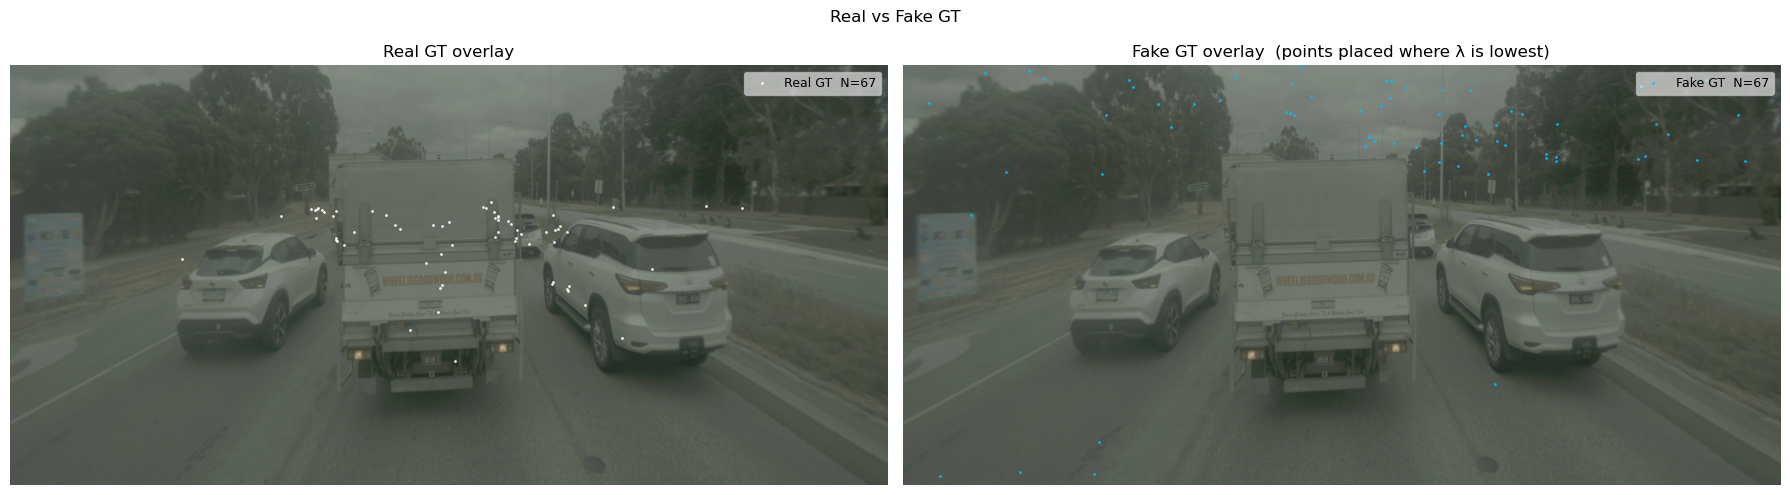

In [ ]:
# ── Build a "very off" fake GT ────────────────────────────────────────────────
# Strategy: place the same number of points as the real GT, but sample their
# pixel locations from the *inverse* intensity (1 / (lambda + eps)).
# This puts points where the model expects almost nothing.

_fake_rng   = np.random.default_rng(42)
_n_fake     = int(gt_support.sum())          # same count as real GT
_eps        = 1e-6

# Inverted probability: high weight where pred_lambda is LOW
_inv_lam    = 1.0 / (pred_lambda.astype(np.float64) + _eps)
_inv_prob   = _inv_lam.ravel() / _inv_lam.sum()

# Draw pixel indices with replacement, then build binary grid
_fake_idx   = _fake_rng.choice(D, size=_n_fake, replace=False, p=_inv_prob)
fake_gt     = np.zeros(D, dtype=np.float64)
fake_gt[_fake_idx] = 1.0
fake_gt     = fake_gt.reshape(H, W)

print(f"Real GT  point count : {int(gt_support.sum())}")
print(f"Fake GT  point count : {int(fake_gt.sum())}")
print(f"Overlap (pixels)     : {int((fake_gt * (gt_support > 0)).sum())}")

# ── Display: image + fake GT overlay ─────────────────────────────────────────
_fys, _fxs = np.where(fake_gt > 0)

fig_fake, axes_fake = plt.subplots(1, 2, figsize=(18, 5))

axes_fake[0].imshow(img, aspect="auto")
_gys, _gxs = np.where(gt_support > 0)
axes_fake[0].scatter(_gxs, _gys, s=GT_DOT_SIZE, c="white", linewidths=0,
                     alpha=0.9, label=f"Real GT  N={int(gt_support.sum())}")
axes_fake[0].legend(loc="upper right", fontsize=9, framealpha=0.6)
axes_fake[0].axis("off")
axes_fake[0].set_title("Real GT overlay")

axes_fake[1].imshow(img, aspect="auto")
axes_fake[1].scatter(_fxs, _fys, s=GT_DOT_SIZE, c="deepskyblue", linewidths=0,
                     alpha=0.9, label=f"Fake GT  N={int(fake_gt.sum())}")
axes_fake[1].legend(loc="upper right", fontsize=9, framealpha=0.6)
axes_fake[1].axis("off")
axes_fake[1].set_title("Fake GT overlay  (points placed where λ is lowest)")

plt.suptitle("Real vs Fake GT", fontsize=12)
plt.tight_layout()
plt.show()

# ── Projection analysis with fake GT ─────────────────────────────────────────
proj_fake = evaluate_projections(
    pred_lambda,
    fake_gt,
    n_samples     = N_SAMP_EVAL,
    n_projections = N_PROJ_EVAL,
    rng           = np.random.default_rng(PROJ_RNG_SEED),
)
q_fake = proj_fake["quantiles"]

print(f"\nFake GT quantile statistics:")
print(f"  mean  = {q_fake.mean():.4f}  (ideal ≈ 0.50)")
print(f"  std   = {q_fake.std():.4f}  (ideal ≈ 0.289)")
print(f"  frac [.05,.95] = {((q_fake >= 0.05) & (q_fake <= 0.95)).mean():.3f}  (ideal ≈ 0.90)")

# ── Plot ──────────────────────────────────────────────────────────────────────
fig_fq, axes_fq = plt.subplots(1, 2, figsize=(13, 4))

axes_fq[0].hist(q_fake, bins=25, range=(0, 1), color="darkorange",
                edgecolor="white", linewidth=0.4, density=True)
axes_fq[0].axhline(1.0, color="tomato", linewidth=1.5, linestyle="--",
                   label="Uniform[0,1]")
axes_fq[0].set_xlabel("GT quantile  q_k")
axes_fq[0].set_ylabel("Density")
axes_fq[0].set_title(f"Fake GT quantile histogram  ({N_PROJ_EVAL} projections, {N_SAMP_EVAL} samples)")
axes_fq[0].set_xlim(0, 1)
axes_fq[0].legend(fontsize=9)

sorted_qf = np.sort(q_fake)
uniform   = np.linspace(0, 1, N_PROJ_EVAL)
axes_fq[1].plot(uniform, sorted_qf, color="darkorange", linewidth=1.5,
                label="Observed quantiles (fake GT)")
axes_fq[1].plot([0, 1], [0, 1], color="tomato", linewidth=1.5,
                linestyle="--", label="Ideal (uniform)")
axes_fq[1].set_xlabel("Expected quantile (uniform)")
axes_fq[1].set_ylabel("Observed quantile")
axes_fq[1].set_title("QQ plot vs Uniform[0,1]  (fake GT)")
axes_fq[1].set_aspect("equal")
axes_fq[1].legend(fontsize=9)

plt.tight_layout()
plt.show()

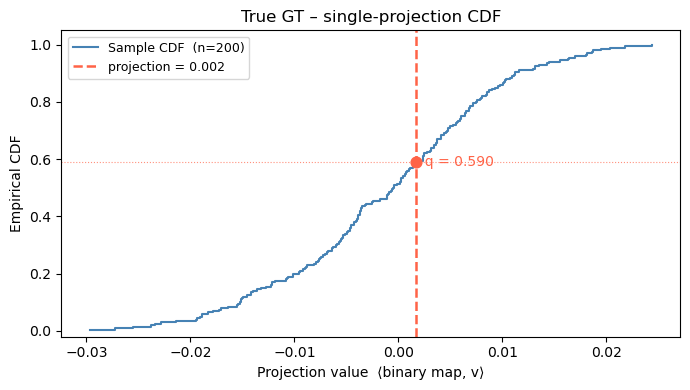

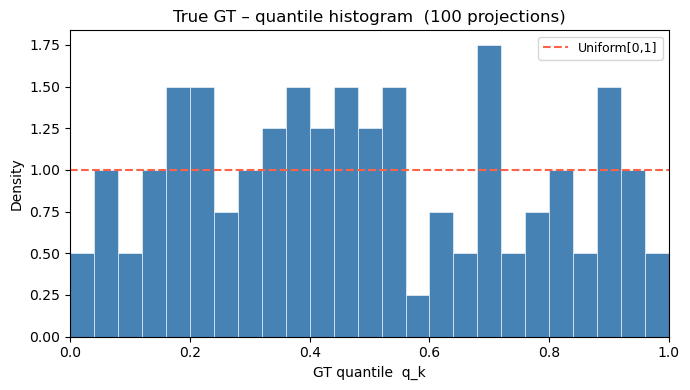

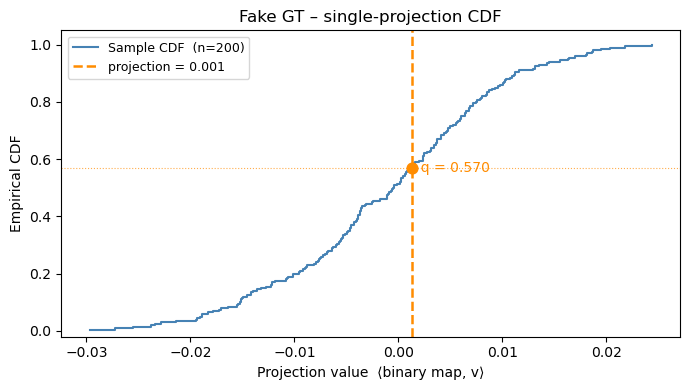

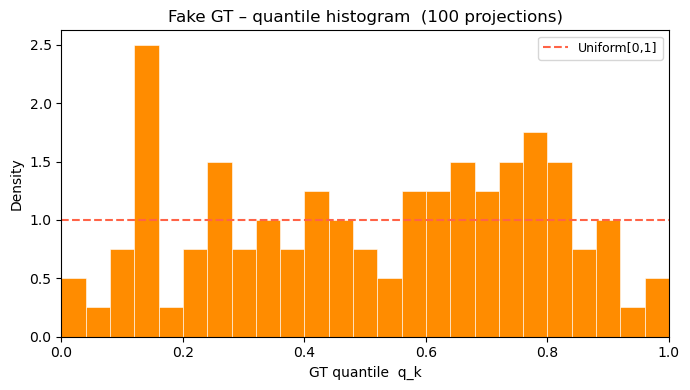

In [32]:
# ── Fake GT projected onto the same single vector v used for the real GT CDF ──
fake_proj     = fake_gt.ravel() @ v                      # scalar
fake_quantile = (sample_projs <= fake_proj).mean()       # where it sits among samples

_cdf_y   = np.arange(1, N_SAMP_EVAL + 1) / N_SAMP_EVAL
_sorted_s = np.sort(sample_projs)
_uniform  = np.linspace(0, 1, N_PROJ_EVAL)


def _plot_cdf(ax, marker_val, marker_q, color, title):
    ax.step(_sorted_s, _cdf_y, where="post", color="steelblue",
            linewidth=1.5, label=f"Sample CDF  (n={N_SAMP_EVAL})")
    ax.axvline(marker_val, color=color, linewidth=1.8, linestyle="--",
               label=f"projection = {marker_val:.3f}")
    ax.axhline(marker_q, color=color, linewidth=0.8, linestyle=":", alpha=0.7)
    ax.scatter([marker_val], [marker_q], color=color, zorder=5, s=60)
    ax.annotate(f"  q = {marker_q:.3f}", xy=(marker_val, marker_q),
                fontsize=10, color=color, va="center")
    ax.set_xlabel("Projection value  ⟨binary map, v⟩")
    ax.set_ylabel("Empirical CDF")
    ax.set_title(title)
    ax.legend(fontsize=9)
    ax.set_ylim(-0.02, 1.05)


def _plot_uniform(ax, q_vals, color, title):
    ax.hist(q_vals, bins=25, range=(0, 1), color=color,
            edgecolor="white", linewidth=0.4, density=True)
    ax.axhline(1.0, color="tomato", linewidth=1.5, linestyle="--",
               label="Uniform[0,1]")
    ax.set_xlabel("GT quantile  q_k")
    ax.set_ylabel("Density")
    ax.set_title(title)
    ax.set_xlim(0, 1)
    ax.legend(fontsize=9)


# ── Figure 1 · True GT – CDF ──────────────────────────────────────────────────
fig1_4, ax1_4 = plt.subplots(figsize=(7, 4))
_plot_cdf(ax1_4, gt_proj, gt_quantile, "tomato",
          "True GT – single-projection CDF")
plt.tight_layout(); plt.show()

# ── Figure 2 · True GT – Uniform eval ────────────────────────────────────────
fig2_4, ax2_4 = plt.subplots(figsize=(7, 4))
_plot_uniform(ax2_4, q, "steelblue",
              f"True GT – quantile histogram  ({N_PROJ_EVAL} projections)")
plt.tight_layout(); plt.show()

# ── Figure 3 · Fake GT – CDF ──────────────────────────────────────────────────
fig3_4, ax3_4 = plt.subplots(figsize=(7, 4))
_plot_cdf(ax3_4, fake_proj, fake_quantile, "darkorange",
          "Fake GT – single-projection CDF")
plt.tight_layout(); plt.show()

# ── Figure 4 · Fake GT – Uniform eval ────────────────────────────────────────
fig4_4, ax4_4 = plt.subplots(figsize=(7, 4))
_plot_uniform(ax4_4, q_fake, "darkorange",
              f"Fake GT – quantile histogram  ({N_PROJ_EVAL} projections)")
plt.tight_layout(); plt.show()